<a href="https://colab.research.google.com/github/Darioldeveloper-dev/CSC4110-G01/blob/main/G01_U9_2_responsible_ai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 4110 Machine Learning
## Group G01: Student Performance Factors
### Task 9.2: Responsible AI and Model Card

- **Registration number:** COM/00/23
- **owner:** Whole group (each member writes at least one part and makes at least one GitHub commit)
- **Module:** 10

**Contents**
1. Setup and predictions
2. Fairness check
3. Identifier and leakage check
4. Model card
5. Written answer

In [1]:
# Mount Drive, import libraries, load the saved model and rebuild the same test set as Task 9.1
from google.colab import drive
drive.mount('/content/drive')
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

base = Path("/content/drive/MyDrive/CSC4110_G01")
model = joblib.load(base / "models" / "G01_model.joblib")
df = pd.read_csv(base / "data" / "stage1_students.csv")
df['high_score'] = (df['Exam_Score'] >= 70).astype(int)

# Keep ALL columns in the split so Gender and School_Type are available for the fairness check
model_features = list(model.feature_names_in_)
X_all = df.drop(columns=['Exam_Score', 'high_score'])
y = df['high_score']
X_train_all, X_test_all, y_train, y_test = train_test_split(X_all, y, test_size=0.2, random_state=42, stratify=y)
THRESHOLD = 0.30   # the decision rule used by the app
proba = model.predict_proba(X_test_all[model_features])[:, 1]
pred = (proba >= THRESHOLD).astype(int)
print("Model features:", model_features)
print("Test rows:", len(X_test_all), "| overall recall at 0.30:", round(recall_score(y_test, pred), 4))

Mounted at /content/drive
Model features: ['Hours_Studied', 'Attendance', 'Previous_Scores', 'Motivation_Level', 'Parental_Involvement', 'Access_to_Resources']
Test rows: 1322 | overall recall at 0.30: 0.8585


  attribute   group  test_rows  actual_high_scorers  recall
     Gender  Female        555                  127  0.8504
     Gender    Male        767                  198  0.8636
School_Type Private        412                  101  0.8515
School_Type  Public        910                  224  0.8616

Recall gap within each attribute: {'Gender': 0.0132, 'School_Type': 0.0101}


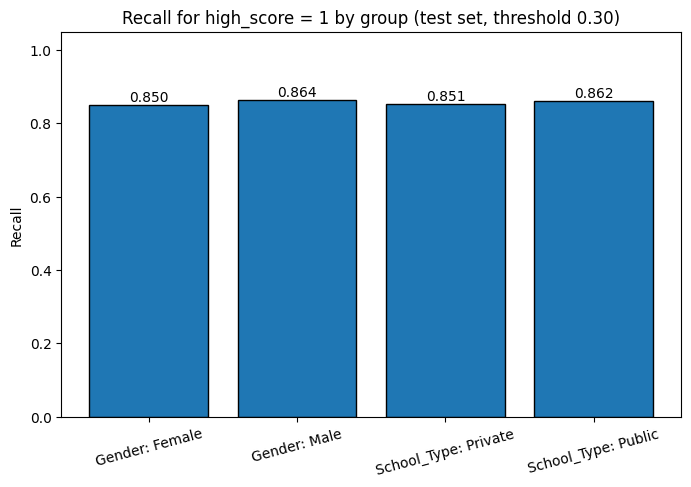

In [2]:
# Part (a): recall for high_score = 1 by Gender and by School_Type, with the number of test rows
rows = []
for col in ['Gender', 'School_Type']:
    for group in sorted(X_test_all[col].unique()):
        mask = (X_test_all[col] == group).values
        rows.append({'attribute': col, 'group': group, 'test_rows': int(mask.sum()),
                     'actual_high_scorers': int(y_test[mask].sum()),
                     'recall': recall_score(y_test[mask], pred[mask])})
fairness_table = pd.DataFrame(rows)
print(fairness_table.round(4).to_string(index=False))
gaps = fairness_table.groupby('attribute')['recall'].agg(lambda s: s.max() - s.min())
print("\nRecall gap within each attribute:", gaps.round(4).to_dict())

# Save the table and a bar chart
fairness_table.to_csv(base / "outputs" / "fairness.csv", index=False)
labels = fairness_table['attribute'] + ': ' + fairness_table['group']
plt.figure(figsize=(8, 5))
plt.bar(labels, fairness_table['recall'], edgecolor='black')
for i, v in enumerate(fairness_table['recall']):
    plt.text(i, v + 0.01, f'{v:.3f}', ha='center')
plt.ylim(0, 1.05)
plt.title('Recall for high_score = 1 by group (test set, threshold 0.30)')
plt.ylabel('Recall')
plt.xticks(rotation=15)
plt.savefig(base / "outputs" / "fairness.png", dpi=150, bbox_inches='tight')
plt.show()

In [3]:
# Part (b) step 1: flag any feature name that looks like a personal identifier
clean = pd.read_csv(base / "data" / "clean_students.csv")
candidates = [col for col in clean.columns if col not in ['Exam_Score', 'high_score']]
def looks_like_identifier(name):
    # an identifier is a name with the word id, name, phone or email in it (split at underscores)
    tokens = name.lower().split('_')
    return any(t in ('id', 'name', 'phone', 'email') or t.endswith('id') and len(t) <= 4 for t in tokens)
print("Features of the deployed model:", model_features)
print("All candidate features:", candidates)
flagged = [col for col in candidates if looks_like_identifier(col)]
print("Flagged as identifiers:", flagged)

# Part (b) step 2: features with a correlation above 0.95 with the target
corr = clean[candidates].corrwith(clean['high_score']).abs().sort_values(ascending=False)
print(corr.head(5).round(4))
too_correlated = list(corr[corr > 0.95].index)
print("Correlation above 0.95:", too_correlated)

# Part (b) step 3: confirm Exam_Score is not a feature of the classifier
print("Exam_Score is a feature of the classifier:", 'Exam_Score' in model_features)

Features of the deployed model: ['Hours_Studied', 'Attendance', 'Previous_Scores', 'Motivation_Level', 'Parental_Involvement', 'Access_to_Resources']
All candidate features: ['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'School_Type_Private', 'School_Type_Public', 'Gender_Female', 'Gender_Male', 'effort']
Flagged as identifiers: []
effort                 0.5760
Attendance             0.4949
Hours_Studied          0.3717
Access_to_Resources    0.1566
Previous_Scores        0.1469
dtype: float64
Correlation above 0.95: []
Exam_Score is a feature of the classifier: False


In [4]:
# Part (c): compute the test numbers that go into the model card
auc = roc_auc_score(y_test, proba)
perf = {'accuracy': accuracy_score(y_test, pred), 'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred), 'f1': f1_score(y_test, pred), 'auc': auc}
print({k: round(v, 4) for k, v in perf.items()})

{'accuracy': 0.9024, 'precision': 0.7707, 'recall': 0.8585, 'f1': 0.8122, 'auc': np.float64(0.95)}


In [5]:
# Part (c): write report/model_card.md with the headings required by the brief, filled with this run's numbers
card = f"""# Model card: scholarship nomination helper (Group G01)

## Model purpose
Estimate the probability that a secondary-school student scores 70 or more in the examination (high_score = 1), so that Elimu Bora Trust can shortlist students for a mentorship scholarship interview.

## Intended users
Elimu Bora Trust programme staff and teachers in the 40 partner schools in Bungoma County. The output supports a human decision; it does not replace it.

## Data source and licence
Student Performance Factors, a public dataset of {len(df):,} student records (20 columns). Owner, link, licence and download date are recorded in the Task 1 notebook (G01_T01_setup.ipynb). The data is not from Elimu Bora schools, so the model has not yet been tested on them.

## Features used
{', '.join(model_features)}. Exam_Score is not a feature. No personal identifier is used (flagged names: {flagged if flagged else 'none'}). No candidate feature has a correlation above 0.95 with the target (largest: {corr.index[0]}, {corr.iloc[0]:.2f}).

## Performance on test data
Logistic regression on {len(X_test_all):,} held-out students (20% stratified split, random_state=42), decision threshold {THRESHOLD}:
accuracy {perf['accuracy']:.3f}, precision {perf['precision']:.3f}, recall {perf['recall']:.3f}, F1 {perf['f1']:.3f}, AUC {perf['auc']:.3f}.

## Fairness check results
Recall for high_score = 1 by group (test rows in brackets):
{chr(10).join(f"- {r.attribute} = {r.group}: recall {r.recall:.3f} ({r.test_rows} students, {r.actual_high_scorers} high scorers)" for r in fairness_table.itertuples())}
Largest gap within an attribute: {gaps.idxmax()} ({gaps.max():.3f}).

## Limitations
- Trained on a public dataset, not on Bungoma County schools; scores may differ there.
- Uses six inputs only, so it is less accurate than a model using all 20 columns.
- Precision at threshold {THRESHOLD} is {perf['precision']:.2f}: some students flagged will not reach 70.
- Past performance and attendance dominate the prediction, so late improvers can be missed.
- Self-reported inputs (hours studied, motivation) may be inaccurate.

## Who should not use the model
Anyone who wants to decide a student's grade, placement, discipline or fees; anyone using it on a different age group or curriculum without re-testing; anyone using it as the only basis for refusing a scholarship.

## Testing before release
- Test set: the {len(X_test_all):,} held-out students above, never used for training or tuning.
- Scores the model must reach: recall of at least 0.80 for high_score = 1 overall and in every Gender and School_Type group, and AUC of at least 0.90.
- Pilot: a small group of Trust staff and two or three volunteer schools use the app first, and their teachers compare its suggestions with their own shortlist before any wider release.

## Rule for schools
The model must never be used to lower expectations for any student: a low probability is not a reason to withhold support, teaching time or encouragement.
"""
(base / "report" / "model_card.md").write_text(card)
print(card)

# Model card: scholarship nomination helper (Group G01)

## Model purpose
Estimate the probability that a secondary-school student scores 70 or more in the examination (high_score = 1), so that Elimu Bora Trust can shortlist students for a mentorship scholarship interview.

## Intended users
Elimu Bora Trust programme staff and teachers in the 40 partner schools in Bungoma County. The output supports a human decision; it does not replace it.

## Data source and licence
Student Performance Factors, a public dataset of 6,607 student records (20 columns). Owner, link, licence and download date are recorded in the Task 1 notebook (G01_T01_setup.ipynb). The data is not from Elimu Bora schools, so the model has not yet been tested on them.

## Features used
Hours_Studied, Attendance, Previous_Scores, Motivation_Level, Parental_Involvement, Access_to_Resources. Exam_Score is not a feature. No personal identifier is used (flagged names: none). No candidate feature has a correlation above 0.95 

In [6]:
# Self-check: graded variables and files
assert set(['attribute', 'group', 'test_rows', 'recall']) <= set(fairness_table.columns)
assert (base / 'outputs' / 'fairness.csv').exists() and (base / 'outputs' / 'fairness.png').exists()
assert isinstance(flagged, list) and 'Exam_Score' not in model_features
text = (base / 'report' / 'model_card.md').read_text()
for h in ['Model purpose', 'Intended users', 'Data source and licence', 'Features used', 'Performance on test data',
          'Fairness check results', 'Limitations', 'Who should not use the model', 'Testing before release']:
    assert h in text, h
print("Task 9.2 checks passed")

Task 9.2 checks passed


### Fairness Audit Findings and Organisational Recommendations

Across our fairness audit at the `0.30` decision threshold, the largest recall gap appeared across **gender** at **`0.0132`** (`1.32` percentage points), with female students achieving `0.8504` recall (`127` high scorers out of `555`) compared to `0.8636` for male students (`198` out of `767`), while `School_Type` showed an even smaller gap of `0.0101` (`0.8515` Private vs. `0.8616` Public). Because each subgroup contains roughly `100` to `200` high scorers, a one-percentage-point difference sits well within normal random sampling variation rather than indicating systematic bias. To ensure equitable deployment, the Trust should keep demographic attributes like `Gender` and `School_Type` strictly excluded from the model's inputs, validate subgroup recall directly on its own schools during a controlled pilot before full rollout, and continuously monitor recall by group after release so that predictions never lower expectations for any student cohort.